# Exploração do Dataset XJTU-SY e Geração dos Escalogramas CWT

**Projeto:** Diagnóstico de Falhas em Rolamentos Industriais via CWT + Deep Learning  
**Dataset:** Xi'an Jiaotong University & Sumyoung Technology (XJTU-SY Bearing Dataset)  
**Objetivo:** Explorar os sinais de vibração contínuos de **25.6 kHz** do ensaio acelerado de degradação (*run-to-failure*), comparar as condições saudáveis e defeituosas (pistas interna e externa) e gerar o dataset balanceado de escalogramas CWT ($224 \times 224$ pixels) sem vazamento de dados (*data leakage*).

---


## 1. Importação dos Módulos e Parâmetros Globais


In [1]:
import sys
from pathlib import Path

# Adicionar raiz do projeto ao sys.path
BASE_DIR = Path.cwd().parent.parent if Path.cwd().name in ['1_cwru', '2_paderborn', '3_xjtu', '4_cross_domain_tempo', '5_order_tracking', '6_confronto_final'] else Path.cwd().parent
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import numpy as np
import matplotlib.pyplot as plt

from src.config import (
    XJTU_RAW_DIR,
    XJTU_PROCESSED_DIR,
    XJTU_CLASSES,
    XJTU_FS,
    XJTU_WINDOW_SIZE,
    XJTU_FREQ_MIN,
    XJTU_FREQ_MAX
)
from src.dataset_xjtu import load_xjtu_csv_file, segment_xjtu_signal, get_xjtu_manifest, extract_xjtu_rpm
from src.generate_dataset_xjtu import compute_xjtu_cwt, process_and_generate_xjtu_dataset

## 2. Resumo das Configurações do Dataset XJTU-SY


In [2]:
print("=" * 60)
print(" CONFIGURAÇÕES DO DATASET XJTU-SY ")
print("=" * 60)
print(f"Taxa de Amostragem (Fs)  : {XJTU_FS:,} Hz (25.6 kHz)")
print(f"Comprimento da Janela     : {XJTU_WINDOW_SIZE} amostras (~{XJTU_WINDOW_SIZE/XJTU_FS*1000:.1f} ms)")
print(f"Faixa de Frequência CWT   : {XJTU_FREQ_MIN} Hz a {XJTU_FREQ_MAX:,} Hz")
print(f"Classes Mapeadas          : {XJTU_CLASSES}")
print("=" * 60)


 CONFIGURAÇÕES DO DATASET XJTU-SY 
Taxa de Amostragem (Fs)  : 25,600 Hz (25.6 kHz)
Comprimento da Janela     : 2048 amostras (~80.0 ms)
Faixa de Frequência CWT   : 10 Hz a 10,000 Hz
Classes Mapeadas          : ['normal', 'inner_race', 'outer_race']


## 3. Carregamento e Comparação dos Sinais de Vibração (25.6 kHz)

Carregamos um sinal de cada condição a partir do manifesto:
* **Normal:** Início do ensaio do rolamento saudável.
* **Pista Interna:** Estágio final com dano severo de pista interna.
* **Pista Externa:** Estágio final com falha por fadiga na pista externa.


In [3]:
manifest = get_xjtu_manifest(max_files_per_class=30)

sample_normal = manifest["normal"][0]
sample_inner  = manifest["inner_race"][-1]
sample_outer  = manifest["outer_race"][-1]

sig_normal = load_xjtu_csv_file(sample_normal, channel=0)
sig_inner  = load_xjtu_csv_file(sample_inner, channel=0)
sig_outer  = load_xjtu_csv_file(sample_outer, channel=0)

print(f"[+] Normal     : {len(sig_normal):,} amostras ({sample_normal.parent.name}/{sample_normal.name}) | RPM: {extract_xjtu_rpm(sample_normal)}")
print(f"[+] Inner Race : {len(sig_inner):,} amostras ({sample_inner.parent.name}/{sample_inner.name}) | RPM: {extract_xjtu_rpm(sample_inner)}")
print(f"[+] Outer Race : {len(sig_outer):,} amostras ({sample_outer.parent.name}/{sample_outer.name}) | RPM: {extract_xjtu_rpm(sample_outer)}")


[+] Normal     : 32,768 amostras (Bearing1_1/1.csv) | RPM: 2100.0
[+] Inner Race : 32,768 amostras (Bearing3_4/1507.csv) | RPM: 2400.0
[+] Outer Race : 32,768 amostras (Bearing3_5/106.csv) | RPM: 2400.0


## 4. Visualização dos Sinais no Domínio do Tempo e Escalogramas CWT


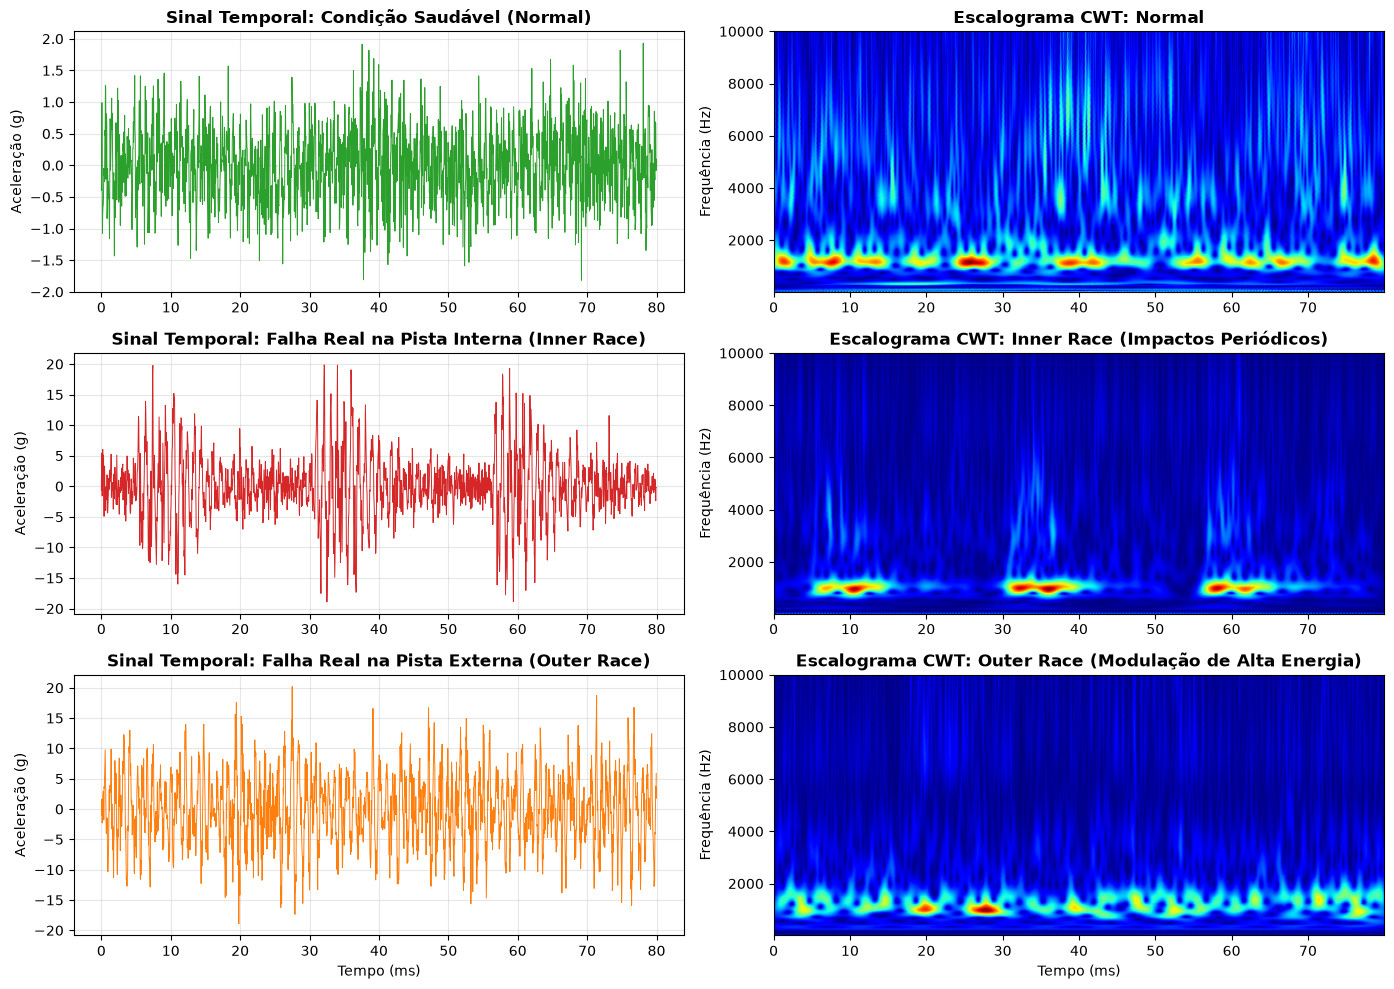

In [4]:
# Extrair primeira janela de cada sinal para visualização
win_norm = sig_normal[:XJTU_WINDOW_SIZE]
win_in = sig_inner[:XJTU_WINDOW_SIZE]
win_out = sig_outer[:XJTU_WINDOW_SIZE]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
t = np.arange(XJTU_WINDOW_SIZE) / XJTU_FS * 1000  # ms
extent_cwt = [t[0], t[-1], XJTU_FREQ_MIN, XJTU_FREQ_MAX]

# 1. Normal
axes[0, 0].plot(t, win_norm, color='#2ca02c', lw=0.7)
axes[0, 0].set_title('Sinal Temporal: Condição Saudável (Normal)', fontweight='bold')
axes[0, 0].set_ylabel('Aceleração (g)')
axes[0, 0].grid(True, alpha=0.3)

cwt_norm = compute_xjtu_cwt(win_norm)
axes[0, 1].imshow(cwt_norm, extent=extent_cwt, cmap='jet', aspect='auto', origin='lower')
axes[0, 1].set_title('Escalograma CWT: Normal', fontweight='bold')
axes[0, 1].set_ylabel('Frequência (Hz)')

# 2. Inner Race
axes[1, 0].plot(t, win_in, color='#d62728', lw=0.7)
axes[1, 0].set_title('Sinal Temporal: Falha Real na Pista Interna (Inner Race)', fontweight='bold')
axes[1, 0].set_ylabel('Aceleração (g)')
axes[1, 0].grid(True, alpha=0.3)

cwt_in = compute_xjtu_cwt(win_in)
axes[1, 1].imshow(cwt_in, extent=extent_cwt, cmap='jet', aspect='auto', origin='lower')
axes[1, 1].set_title('Escalograma CWT: Inner Race (Impactos Periódicos)', fontweight='bold')
axes[1, 1].set_ylabel('Frequência (Hz)')

# 3. Outer Race
axes[2, 0].plot(t, win_out, color='#ff7f0e', lw=0.7)
axes[2, 0].set_title('Sinal Temporal: Falha Real na Pista Externa (Outer Race)', fontweight='bold')
axes[2, 0].set_xlabel('Tempo (ms)')
axes[2, 0].set_ylabel('Aceleração (g)')
axes[2, 0].grid(True, alpha=0.3)

cwt_out = compute_xjtu_cwt(win_out)
axes[2, 1].imshow(cwt_out, extent=extent_cwt, cmap='jet', aspect='auto', origin='lower')
axes[2, 1].set_title('Escalograma CWT: Outer Race (Modulação de Alta Energia)', fontweight='bold')
axes[2, 1].set_xlabel('Tempo (ms)')
axes[2, 1].set_ylabel('Frequência (Hz)')

plt.tight_layout()
plt.show()

## 5. Geração Completa do Dataset XJTU-SY (Particionamento Estrito)

Executamos a geração com separação estrita por Rolamentos Físicos (*Leave-Bearing-Out*) e Falhas Puras (Wang et al., 2020):
- **Treino**: Bearing1_1 (normal), Bearing1_2 (outer_race), Bearing2_1 (inner_race pura)
- **Validação**: Bearing2_2 (normal), Bearing2_4 (outer_race), Bearing3_3 (inner_race pura)
- **Teste**: Bearing3_1 (normal), Bearing3_5 (outer_race), Bearing3_4 (inner_race pura — condição inédita 40 Hz)

> **Nota Anti-Leakage:** 9 rolamentos físicos completamente disjuntos. Falhas combinadas (Bearing1_5 e 3_2) e gaiola 100% excluídas.

In [5]:
# Execute esta célula para gerar as imagens do dataset XJTU-SY com particionamento estrito
process_and_generate_xjtu_dataset()


 GERAÇÃO DO DATASET DE ESCALOGRAMAS CWT — XJTU-SY
    Divisão Estrita: Leave-Bearing-Out com 9 Rolamentos Disjuntos
    Falhas Puras Comprovadas (Wang et al., 2020) — Sem Falhas Combinadas
    Taxa de amostragem: 25600 Hz | Freqs: 10-10000 Hz

[+] Processando classe 'normal'...


    [OK] train (normal): 16 arquivos -> 240 imagens geradas


    [OK]   val (normal): 12 arquivos -> 180 imagens geradas


    [OK]  test (normal): 10 arquivos -> 150 imagens geradas

[+] Processando classe 'inner_race'...


    [OK] train (inner_race): 16 arquivos -> 240 imagens geradas


    [OK]   val (inner_race): 12 arquivos -> 180 imagens geradas


    [OK]  test (inner_race): 10 arquivos -> 150 imagens geradas

[+] Processando classe 'outer_race'...


    [OK] train (outer_race): 16 arquivos -> 240 imagens geradas


    [OK]   val (outer_race): 12 arquivos -> 180 imagens geradas


    [OK]  test (outer_race): 10 arquivos -> 150 imagens geradas

[INFO] Total de 1710 escalogramas gerados e salvos em:
       C:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\data\xjtu\processed
